In [5]:
import xarray as xr
import numpy as np
import pandas as pd

In [ ]:
glac_df = pd.read_parquet("/wolke_scratch/dnikolo/ICON_Data/sedim_search/R2B4/wbf_v3/postprocessing_output/np/20070301.0000_20070315.0000/Agg_03_T_18_12.parquet")

In [19]:
glac_df.model_grid_ncell.iloc[30]

array([array([5080, 5082]), array([5080, 5082]), array([5080, 5082]),
       array([5080, 5082, 5083]), array([5080, 5082, 5083]),
       array([5080, 5082, 5083]), array([5080, 5082, 5083]),
       array([5080, 5082, 5083]), array([5080, 5083]),
       array([5080, 5083]), array([5080, 5083]), array([5080, 5083]),
       array([5080, 5083]), array([5080, 5083]),
       array([5080, 5081, 5083]), array([5083]), array([5083]),
       array([5083]), array([5083]), array([5083]), array([5083]),
       array([5083]), array([5083])], dtype=object)

In [31]:
result = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/sedim_search/R2B4/wbf_v3/bulk_data/sedim_r2b4_wbfv3_bulk_cloud_ml_20070101T000000Z.nc")
ctp = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/sedim_search/R2B4/wbf_v3/raw_data/sedim_r2b4_wbfv3_ctp_2d_ml_20070101T000000Z.nc")
atm_3d = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/sedim_search/R2B4/wbf_v3/raw_data/sedim_r2b4_wbfv3_atm_3d_cloud_ml_20070101T000000Z.nc")

In [ ]:

def extract_cloud_ncell(model_grid_ncell,cloud_location_ind_agg):
    ind1 = cloud_location_ind_agg[0]
    ind2 = cloud_location_ind_agg[1]
    indeces = model_grid_ncell[ind1,ind2]
    if np.isnan(indeces).any():
        raise ValueError("Nans in model ncell indeces??")
    indeces= indeces[~np.isnan(indeces)]
    return np.unique(indeces.astype(int))

In [24]:
aux_data = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/aux_tools/r2b4_grid_ncell_np.nc")

In [29]:
extract_cloud_ncell(aux_data["ncells"].values,(np.array([2,250,250,250]),np.array([3,300,400,500])))

array([4471, 4499, 4515])

0.129248046875

In [47]:
np.isnan(result.ze.isel(time=1).values).all(axis=0).mean()

0.129248046875

In [48]:
np.isnan(result.ze.isel(bulk_level=0,time=1)).mean()


<xarray.DataArray 'ze' ()>
array(0.34589844)
Coordinates:
    time        float64 2.007e+07
    bulk_level  int16 0

In [33]:
time_idx = 55
# cell_idx = 4500 #cloudy but nan values
cell_idx = 2451
cloudy_mask = (atm_3d.cli.isel(time=time_idx, ncells=cell_idx).values + atm_3d.clw.isel(time=time_idx, ncells=cell_idx).values)>1e-5
atm_ze = atm_3d.cloudsat_ze_mean.isel(time=time_idx, ncells=cell_idx).values
output = {
    "cph": ctp.cph.isel(time=time_idx, ncells=cell_idx).values,
    "ctp": ctp.ctp.isel(time=time_idx, ncells=cell_idx).values,
    "ctlev": ctp.ctlev.isel(time=time_idx, ncells=cell_idx).values,
    "result_cph": result.cph.isel(time=time_idx, ncells=cell_idx).values,
    "result_ze": result.ze.isel(time=time_idx, ncells=cell_idx).values,
    "atm_3d_ze": atm_ze,
    "atm_3d_clody": cloudy_mask,
    "atm_zg": atm_3d.zg.isel(ncells=cell_idx).values,
    "cloudy but nan heights":  atm_3d.zg.isel( ncells=cell_idx).values[np.where(np.isnan(atm_ze) & cloudy_mask)[0]]
    
}

output

{'cph': array(1.0003893, dtype=float32),
 'ctp': array(42593.914, dtype=float32),
 'ctlev': array(32., dtype=float32),
 'result_cph': array([1.004214 , 1.004456 , 1.004698 , 1.00494  , 1.005182 , 1.0054241,
        1.0056661, 1.0059307, 1.0062344, 1.0065382, 1.0068418, 1.0071455,
        1.0074493, 1.007753 , 1.0069039, 1.0056291, 1.0043542, 1.0030794,
        1.0018045, 1.0005296, 1.       , 1.       , 1.       , 1.       ,
        1.       ], dtype=float32),
 'result_ze': array([-16.89453  , -16.78196  , -16.66939  , -16.55682  , -16.444248 ,
        -16.331678 , -16.219109 , -16.107328 , -15.996918 , -15.886507 ,
        -15.776096 , -15.665687 , -15.555276 , -15.444866 , -15.430119 ,
        -15.450697 , -15.471275 , -15.491854 , -15.512432 , -15.5330105,
        -16.9257   , -19.293749 , -21.661798 , -24.029848 , -26.397898 ],
       dtype=float32),
 'atm_3d_ze': array([        nan, -27.213884 , -24.479515 , -22.440607 ,         nan,
                nan,         nan,         nan, 

In [29]:
def _depth_from_cloud_top(zg: np.ndarray, cloud_top_height_m: np.ndarray) -> np.ndarray:
    if zg.ndim == 2:
        return cloud_top_height_m[:, None, :] - zg[None, :, :]
    return cloud_top_height_m[:, None, :] - zg

In [35]:
import numpy as np

# Shape: (time=2, model_level=5, cell=3)
var = np.array(
    [
        [
            [10.0, 20.0, 30.0],
            [11.0, 21.0, 31.0],
            [12.0, 22.0, 32.0],
            [13.0, 23.0, 33.0],
            [14.0, 24.0, 34.0],
        ],
        [
            [15.0, 25.0, 35.0],
            [16.0, 26.0, 36.0],
            [17.0, 27.0, 37.0],
            [18.0, 28.0, 38.0],
            [19.0, 29.0, 39.0],
        ],
    ],
    dtype=np.float32,
)

# Model-level heights in metres.
# Shape: (time=2, model_level=5, cell=3)
zg = np.array(
    [
        [
            [3000, 3100, 3200],
            [2500, 2600, 2700],
            [2000, 2100, 2200],
            [1500, 1600, 1700],
            [1000, 1100, 1200],
        ],
        [
            [3100, 3200, 3300],
            [2600, 2700, 2800],
            [2100, 2200, 2300],
            [1600, 1700, 1800],
            [1100, 1200, 1300],
        ],
    ],
    dtype=np.float32,
)

# Shape: (time=2, cell=3)
cloud_top_height_m = np.array(
    [
        [3000, 3100, 3200],
        [3100, 3200, 3300],
    ],
    dtype=np.float32,
)

valid_cloud_top = np.array(
    [
        [True, True, False],
        [True, False, True],
    ],
    dtype=bool,
)

# Three depth intervals below cloud top.
# Shape: (output_layer=3, bounds=2)
bulk_offsets_m = np.array(
    [
        [-100, -500],
        [-500, -1000],
        [-1000, -2000],
    ],
    dtype=np.float32,
)

# Ice and liquid condensate; same shape as var.
cli = np.full(var.shape, 0.0006, dtype=np.float32)
clw = np.full(var.shape, 0.0005, dtype=np.float32)

# Add a few non-cloudy or unavailable values.
cli[0, 2, 1] = 0.0
clw[0, 2, 1] = 0.0
cli[1, 3, 2] = np.nan

dz_m = 100.0
condensate_threshold = 0.001


In [39]:
valid_cloud_top.shape

(2, 3)

In [56]:
import numpy as np

TIME_COUNT = 2
HEIGHT_COUNT = 47
CELL_COUNT = 20

# ICON levels ordered approximately from model top to surface.
height_profile_m = np.linspace(
    20_000.0,
    100.0,
    HEIGHT_COUNT,
    dtype=np.float32,
)

# zg: (height, ncells)
zg = np.broadcast_to(
    height_profile_m[:, None],
    (HEIGHT_COUNT, CELL_COUNT),
)

# Cloud tops vary between cells and times.
cell_phase = np.linspace(
    0.0,
    2.0 * np.pi,
    CELL_COUNT,
    dtype=np.float32,
)[None, :]

time_phase = np.linspace(
    0.0,
    2.0 * np.pi,
    TIME_COUNT,
    dtype=np.float32,
)[:, None]

# Shape: (time, ncells)
cloud_top_height_m = (
    8_000.0
    + 1_000.0 * np.sin(cell_phase)
    + 500.0 * np.cos(time_phase)
).astype(np.float32)

# Mark approximately 90% of cloud tops as valid.
valid_cloud_top = np.ones(
    (TIME_COUNT, CELL_COUNT),
    dtype=bool,
)
valid_cloud_top[:, ::10] = False

# Create vertical profiles and broadcast across time and cells.
# The broadcasted arrays have the correct shapes without allocating
# several hundred MB for each variable.
var_profile = np.linspace(
    -25.0,
    10.0,
    HEIGHT_COUNT,
    dtype=np.float32,
)[None, :, None]

cli_profile = np.linspace(
    0.0,
    1.5e-3,
    HEIGHT_COUNT,
    dtype=np.float32,
)[None, :, None]

clw_profile = np.linspace(
    0.0,
    2.0e-3,
    HEIGHT_COUNT,
    dtype=np.float32,
)[None, :, None]

# Shapes: (time, height, ncells)
var = np.broadcast_to(
    var_profile,
    (TIME_COUNT, HEIGHT_COUNT, CELL_COUNT),
)

cli = np.broadcast_to(
    cli_profile,
    (TIME_COUNT, HEIGHT_COUNT, CELL_COUNT),
)

clw = np.broadcast_to(
    clw_profile,
    (TIME_COUNT, HEIGHT_COUNT, CELL_COUNT),
)

# Output layers expressed as offsets below the cloud top.
# Shape: (layer_count=5, bounds=2)
# bulk_offsets_m = np.array(
#     [
#         [-0.0,    -500.0],
#         [-500.0,  -1_000.0],
#         [-1_000.0, -2_000.0],
#         [-2_000.0, -3_000.0],
#         [-3_000.0, -5_000.0],
#     ],
#     dtype=np.float32,
# )
bulk_offsets_m = np.array(
    [
        [-0.0,    -100.0],
        [-100.0,  -200.0],
        [-200.0, -300.0],
        [-300.0, -400.0],
        [-400.0, -500.0],
    ],
    dtype=np.float32,
)

dz_m = 100.0
condensate_threshold = 1.0e-3

In [ ]:
var[,:,3]

array([-25.        , -24.23913   , -23.47826   , -22.717392  ,
       -21.956522  , -21.195652  , -20.434782  , -19.673914  ,
       -18.913044  , -18.152174  , -17.391304  , -16.630434  ,
       -15.869565  , -15.108696  , -14.347826  , -13.586957  ,
       -12.826087  , -12.065217  , -11.304348  , -10.543478  ,
        -9.782609  ,  -9.021739  ,  -8.26087   ,  -7.5       ,
        -6.7391305 ,  -5.978261  ,  -5.2173915 ,  -4.4565215 ,
        -3.6956522 ,  -2.9347825 ,  -2.173913  ,  -1.4130435 ,
        -0.65217394,   0.10869565,   0.8695652 ,   1.6304348 ,
         2.3913043 ,   3.152174  ,   3.9130435 ,   4.673913  ,
         5.4347825 ,   6.195652  ,   6.9565215 ,   7.7173915 ,
         8.478261  ,   9.23913   ,  10.        ], dtype=float32)

In [105]:
def compute_cloudy(
        cli: np.ndarray,
        clw: np.ndarray, 
        ctmask: np.ndarray, 
        condensate_threshold: float,
        ctmask_threshold: float
    ):
    condensate = cli + clw
    return (
        np.isfinite(cli)
        & np.isfinite(clw)
        & (condensate >= condensate_threshold)
        & np.isfinite(ctmask)[:, None, :]
        & (ctmask[:, None, :] > ctmask_threshold)
    )

In [ ]:
DEFAULT_CTMASK_THRESHOLD=1e-5
def compute_interpolated_layers(
    var: np.ndarray,
    zg: np.ndarray,
    cloud_top_height_m: np.ndarray,
    valid_cloud_top: np.ndarray,
    bulk_offsets_m: np.ndarray,
    cli: np.ndarray,
    clw: np.ndarray,
    null_target: float,
    condensate_threshold: float = 1e-5
) -> tuple[np.ndarray, np.ndarray]:
    time_count, _, cell_count = var.shape
    layer_count = bulk_offsets_m.shape[0]
    
    mean = np.full((time_count, layer_count, cell_count), np.nan, dtype=np.float32)
    is_cloudy = compute_cloudy(cli,clw,valid_cloud_top,condensate_threshold, DEFAULT_CTMASK_THRESHOLD)
    print(is_cloudy.all())
    n_valid = np.zeros((time_count, layer_count, cell_count), dtype=np.int16)
    depth = _depth_from_cloud_top(zg, cloud_top_height_m)

    
    # cloudy_mask = (
    #     valid_cloud_top[:, None, :] &
    #     np.isfinite(cli) &
    #     np.isfinite(clw) &
    #     ((cli+clw)>=condensate_threshold))
    
    top_depth_out = abs(bulk_offsets_m[:,0])
    bottom_depth_out = abs(bulk_offsets_m[:,1])
    mid_depth_out = (top_depth_out + bottom_depth_out)/2
    max_depth = bottom_depth_out.max()
    
    upper_layer_mask = layer_mask = (
            valid_cloud_top
            & np.isfinite(var[:,0,:])
            & np.isfinite(depth[:,0,:])
            & (depth[:,0,:] >=0)
            & (depth[:,0,:] <=max_depth)
            & is_cloudy[:,0,:]
        )
    for model_layer in range(1,zg.shape[0]):
        layer_mask = (
            valid_cloud_top
            & np.isfinite(var[:,model_layer,:])
            & np.isfinite(depth[:,model_layer,:])
            & (depth[:,model_layer,:] >= 0)
            & is_cloudy[:,model_layer,:]
        )
        
        two_valid_lev_mask = upper_layer_mask & layer_mask
        only_upper_mask= upper_layer_mask & (~layer_mask)
        only_lower_mask = (~upper_layer_mask) & layer_mask
        any_layer_mask = upper_layer_mask | layer_mask
        upper_depth =  depth[:,model_layer-1,:]
        current_depth = depth[:,model_layer,:]
        # lower_depth = depth[:,model_layer+1,:]
        # layer_top_depth = current_depth - (current_depth - upper_depth)/2
        # layer_bottom_depth = current_depth + (lower_depth - current_depth)/2
        corresponding_ind = (mid_depth_out[None,:,None] > upper_depth[:,None,:]) & (mid_depth_out[None,:,None] <= current_depth[:,None,:])
        # print(corresponding_ind.shape)
        # print(depth.shape,
        #   var.shape,
        #   mid_depth_out.shape,
        #   layer_top_depth.shape,
        #   layer_mask.shape)
        current_level_val = var[:, model_layer, :]
        upper_level_val = var[:, model_layer-1, :]
        lev_diff=np.where(only_upper_mask,2*(null_target-upper_level_val),np.nan)
        lev_diff=np.where(only_lower_mask,2*(current_level_val-null_target),lev_diff)
        lev_diff = np.where(two_valid_lev_mask, current_level_val-upper_level_val,lev_diff)
        
        bulk_lev_multiplier = np.where(corresponding_ind, (mid_depth_out[None, :, None]- upper_depth[:,None,:])/(current_depth[:,None,:]-upper_depth[:,None,:]),np.nan)
        bulk_lev_multiplier = np.where(only_upper_mask[:,None,:] & (bulk_lev_multiplier>0.5),np.nan,bulk_lev_multiplier)
        bulk_lev_multiplier = np.where(only_lower_mask[:,None,:] & (bulk_lev_multiplier<0.5),np.nan,bulk_lev_multiplier)
        mean = np.where(corresponding_ind & upper_layer_mask[:,None,:],upper_level_val[:,None,:] + bulk_lev_multiplier*lev_diff[:,None,:],mean)
        mean = np.where(corresponding_ind & only_lower_mask[:,None,:], current_level_val[:,None,:] - (1-bulk_lev_multiplier)*lev_diff[:,None,:],mean)

        n_valid = np.where(
            two_valid_lev_mask[:,None,:],
            2,
            n_valid,
        )

        n_valid = np.where(
            (only_upper_mask | only_lower_mask)[:,None,:],
            1,
            n_valid,
        )

        upper_layer_mask = layer_mask 
                            # (depth[:,model_layer,:] <=max_depth))
        
        

    return mean, n_valid


mean, n_valid = compute_interpolated_layers(
    var=var,
    zg=zg,
    cloud_top_height_m=cloud_top_height_m,
    valid_cloud_top=valid_cloud_top,
    bulk_offsets_m=bulk_offsets_m,
    cli=cli,
    clw=clw,
    null_target=-30,
    condensate_threshold=condensate_threshold,
)


False


array([[[        nan,  -7.798191 ,         nan, -17.348503 ,
                 nan,         nan, -26.078259 ,  -6.0828085,
         -25.127127 ,         nan,         nan, -14.287245 ,
                 nan, -12.929678 ,  -2.9331431,  -6.219574 ,
         -22.765415 ,         nan,         nan, -19.859608 ],
        [        nan,  -5.0811296, -29.51133  ,  -6.2429934,
         -20.928295 , -23.947174 , -14.972749 ,  -5.804037 ,
         -13.669832 , -27.487637 ,         nan,  -3.6729572,
         -22.945953 ,  -2.8993936,  -2.7572637,  -2.8050747,
         -10.252857 ,         nan, -20.519356 ,  -8.050555 ],
        [        nan,  -4.9052496, -18.054035 ,  -5.806574 ,
          -9.822783 , -12.8416605,  -5.9448285,  -5.6281576,
          -5.171264 , -15.678583 ,         nan,  -3.4970777,
         -10.433398 ,  -2.723514 ,  -2.5813842,  -2.6291952,
          -2.8617675, -25.63756  ,  -8.35856  ,  -4.3341703],
        [        nan,  -4.72937  ,  -6.5967417,  -5.6306944,
          -5.863268 ,

In [120]:
mean[1,:,:].T

array([[        nan,         nan,         nan,         nan,         nan],
       [ -7.798191 ,  -5.0811296,  -4.9052496,  -4.72937  ,  -4.5534906],
       [        nan, -29.51133  , -18.054035 ,  -6.5967417,  -5.062686 ],
       [-17.348503 ,  -6.2429934,  -5.806574 ,  -5.6306944,  -5.454815 ],
       [        nan, -20.928295 ,  -9.822783 ,  -5.863268 ,  -5.6873884],
       [        nan, -23.947174 , -12.8416605,  -5.911078 ,  -5.7351985],
       [-26.078259 , -14.972749 ,  -5.9448285,  -5.768949 ,  -5.5930696],
       [ -6.0828085,  -5.804037 ,  -5.6281576,  -5.452278 ,  -5.2763987],
       [-25.127127 , -13.669832 ,  -5.171264 ,  -4.9953847,  -4.819505 ],
       [        nan, -27.487637 , -15.678583 ,  -4.447779 ,  -4.2718997],
       [        nan,         nan,         nan,         nan,         nan],
       [-14.287245 ,  -3.6729572,  -3.4970777,  -3.3211985,  -3.145319 ],
       [        nan, -22.945953 , -10.433398 ,  -2.8643053,  -2.6884258],
       [-12.929678 ,  -2.8993936,  -2.

In [94]:
cloud_top_height_m[1,3]

9337.166

In [95]:
zg[:,3]

array([20000.    , 19567.39  , 19134.783 , 18702.174 , 18269.564 ,
       17836.957 , 17404.348 , 16971.738 , 16539.13  , 16106.521 ,
       15673.913 , 15241.305 , 14808.695 , 14376.087 , 13943.479 ,
       13510.869 , 13078.261 , 12645.652 , 12213.044 , 11780.435 ,
       11347.826 , 10915.218 , 10482.608 , 10050.    ,  9617.392 ,
        9184.782 ,  8752.174 ,  8319.565 ,  7886.9565,  7454.3477,
        7021.7393,  6589.1304,  6156.522 ,  5723.913 ,  5291.304 ,
        4858.696 ,  4426.087 ,  3993.4783,  3560.8696,  3128.261 ,
        2695.652 ,  2263.0435,  1830.4348,  1397.826 ,   965.2174,
         532.6087,   100.    ], dtype=float32)

In [ ]:
var[1,:,3]

array([-25.        , -24.23913   , -23.47826   , -22.717392  ,
       -21.956522  , -21.195652  , -20.434782  , -19.673914  ,
       -18.913044  , -18.152174  , -17.391304  , -16.630434  ,
       -15.869565  , -15.108696  , -14.347826  , -13.586957  ,
       -12.826087  , -12.065217  , -11.304348  , -10.543478  ,
        -9.782609  ,  -9.021739  ,  -8.26087   ,  -7.5       ,
        -6.7391305 ,  -5.978261  ,  -5.2173915 ,  -4.4565215 ,
        -3.6956522 ,  -2.9347825 ,  -2.173913  ,  -1.4130435 ,
        -0.65217394,   0.10869565,   0.8695652 ,   1.6304348 ,
         2.3913043 ,   3.152174  ,   3.9130435 ,   4.673913  ,
         5.4347825 ,   6.195652  ,   6.9565215 ,   7.7173915 ,
         8.478261  ,   9.23913   ,  10.        ], dtype=float32)

In [21]:
vertical = np.array([-11.985348  ,          np.nan,          np.nan,          np.nan,
          1.5907934 ,          np.nan,          np.nan,          np.nan,
          1.6950742 ,          np.nan,          np.nan,   1.5527712 ,
                 np.nan,          np.nan,   0.5864266 ,          np.nan,
         -0.13703516,          np.nan,  -1.7316775 ,          np.nan,
         -3.092356  ,  -5.301631  ,  -6.3149204 ,          np.nan,
                 np.nan], dtype=np.float32)

In [47]:
x = np.arange(vertical.size)
nan_mask = np.isnan(vertical)

vertical[nan_mask] = np.interp(
    x[nan_mask],
    x[~nan_mask],
    vertical[~nan_mask],
)

In [51]:
import matplotlib.pyplot as plt

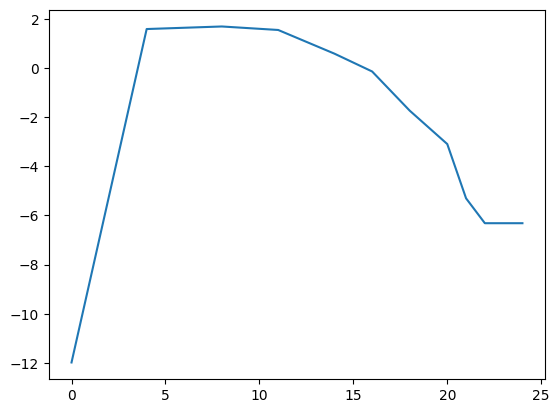

In [52]:
plt.plot(vertical)

In [ ]:
atm_3d = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/cosp_dardar_runs/R2B4/wbf_v3/raw_data/sedim_r2b4_wbfv3_atm_3d_cloud_ml_20071221T000000Z.nc")
ct = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/cosp_dardar_runs/R2B4/wbf_v3/raw_data/sedim_r2b4_wbfv3_ctp_2d_ml_20071221T000000Z.nc")

In [3]:
import numpy as np
import xarray as xr

ctmask_3d = (
    ct["ctmask"]
    .expand_dims(height=atm_3d.height)
    .broadcast_like(atm_3d["cli"])
    .transpose("time", "height", "ncells")
)
CPH = xr.where(((ctmask_3d>1e-5) & ((atm_3d["cli"]+atm_3d["clw"])>=1e-5)),(atm_3d["cli"]/(atm_3d["cli"]+atm_3d["clw"])+1),0)

# ctlev is probably 1-based because height is 1..47
# Convert model level number to zero-based positional index
ctlev_idx = ct["ctlev"].astype(float)

rel_level = xr.DataArray(
    np.arange(4),
    dims="rel_level",
    coords={"rel_level": np.arange(4)}
)

# cloud top + 1/2/3 levels below
target_idx = ctlev_idx + rel_level
nlev = atm_3d.sizes["height"]

valid = (
    np.isfinite(target_idx) &
    (target_idx >= 0) &
    (target_idx < nlev)
)

target_idx_safe = (
    target_idx
    .where(valid, 0)
    .astype(int)
)

CPH_ct_profile = (
    CPH
    .isel(height=target_idx_safe)
    .where(valid, other=0)
    .transpose("time", "rel_level", "ncells")
)

In [4]:
atm_3d

<xarray.Dataset>
Dimensions:                  (ncells: 20480, vertices: 3, height: 47, bnds: 2,
                              time: 96)
Coordinates:
    clon                     (ncells) float32 ...
    clat                     (ncells) float32 ...
  * height                   (height) float64 1.0 2.0 3.0 4.0 ... 45.0 46.0 47.0
  * time                     (time) float64 2.007e+07 2.007e+07 ... 2.007e+07
Dimensions without coordinates: ncells, vertices, bnds
Data variables:
    clon_bnds                (ncells, vertices) float32 ...
    clat_bnds                (ncells, vertices) float32 ...
    height_bnds              (height, bnds) float64 ...
    ps                       (time, ncells) float32 ...
    pfull                    (time, height, ncells) float32 ...
    ta                       (time, height, ncells) float32 ...
    clw                      (time, height, ncells) float32 ...
    cli                      (time, height, ncells) float32 ...
    cl                       (time, height, ncells) float32 ...
    cloudsat_ze_mean         (time, height, ncells) float32 ...
    cloudsat_ze_linear_mean  (time, height, ncells) float32 ...
    zg                       (height, ncells) float32 ...
Attributes:
    CDI:                  Climate Data Interface version 1.8.3rc (http://mpim...
    Conventions:          CF-1.6
    number_of_grid_used:  5
    grid_file_uri:        http://icon-downloads.mpimet.mpg.de/grids/public/ic...
    uuidOfHGrid:          6dffb27e-c162-11e6-bde4-f3bd241f4de0
    uuidOfVGrid:          75ae1dba-8996-102c-7d45-dfaaabcd2a80
    institution:          Max Planck Institute for Meteorology/Deutscher Wett...
    title:                ICON simulation
    source:               git@git.iac.ethz.ch:hammoz/icon-for-hammoz.git@bb3b...
    history:              /capstor/store/cscs/userlab/lp88/dnikolov/icon-for-...
    references:           see MPIM/DWD publications
    comment:              Dragomir Nikolov, ETHZ (dnikolov) on nid005264 (Lin...

In [5]:
atm_3d["zg"].isel(ncells=1 ).values

array([80046.695  , 74659.77   , 70018.84   , 65768.69   , 61816.67   ,
       58112.832  , 54624.633  , 51328.7    , 48207.125  , 45245.613  ,
       42432.375  , 39757.484  , 37212.4    , 34789.688  , 32482.803  ,
       30285.912  , 28193.783  , 26201.697  , 24305.365  , 22500.87   ,
       20784.627  , 19153.338  , 17603.957  , 16134.173  , 14741.227  ,
       13422.394  , 12175.843  , 10999.651  ,  9892.071  ,  8851.512  ,
        7876.5186 ,  6965.7456 ,  6117.9287 ,  5331.85   ,  4606.306  ,
        3940.0842 ,  3331.9417 ,  2780.6082 ,  2284.8052 ,  1843.2899 ,
        1454.9222 ,  1118.755  ,   834.149  ,   600.92194,   419.5749 ,
         292.2258 ,   222.46617], dtype=float32)

In [6]:
heights = atm_3d["zg"].isel(ncells=1 ).values
(heights[:-1]- heights[1:])/1000

array([5.386922  , 4.6409297 , 4.2501564 , 3.9520156 , 3.7038398 ,
       3.4881992 , 3.2959335 , 3.1215742 , 2.9615116 , 2.8132384 ,
       2.6748905 , 2.545086  , 2.422711  , 2.3068848 , 2.1968906 ,
       2.092129  , 1.9920859 , 1.896332  , 1.804496  , 1.7162422 ,
       1.631289  , 1.5493809 , 1.4697841 , 1.3929462 , 1.318833  ,
       1.2465508 , 1.1761914 , 1.1075801 , 1.0405595 , 0.97499317,
       0.9107729 , 0.8478169 , 0.78607863, 0.7255439 , 0.6662219 ,
       0.60814255, 0.5513335 , 0.49580297, 0.44151527, 0.38836768,
       0.33616725, 0.284606  , 0.23322704, 0.18134704, 0.1273491 ,
       0.06975963], dtype=float32)

In [7]:
for i in range(len(heights)):
    print(np.sum(heights))

1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8
1121772.8


In [8]:
atm_3d["zg"].isel(height=20,ncells=1 ).values

array(20784.627, dtype=float32)

In [ ]:
import numpy as np
import xarray as xr


# ============================================================
# User settings
# ============================================================

max_depth_m = 3000
dz_m = 120.0

# Change these if your variable names are different
zg_name = "zg"
ze_name = "cloudsat_ze_mean"
iwc_name = "cli"

# If ctlev ranges from 1..47, set this to True.
# If ctlev ranges from 0..46, set this to False.
ctlev_is_one_based = False


# ============================================================
# Target cloud-top-relative vertical grid
# ============================================================

# Bin centers: 60, 180, ..., 2100 m
depth_bins = xr.DataArray(
    np.arange(dz_m / 2, max_depth_m, dz_m),
    dims="depth_bin",
    coords={"depth_bin": np.arange(dz_m / 2, max_depth_m, dz_m)},
    name="depth_below_ct_m",
)

depth_bins.attrs["long_name"] = "Depth below cloud top"
depth_bins.attrs["units"] = "m"


# ============================================================
# Cloud-top level handling
# ============================================================

nlev = atm_3d.sizes["height"]

ctlev_raw = ct["ctlev"].astype(float)

if ctlev_is_one_based:
    ctlev_idx = ctlev_raw - 1
else:
    ctlev_idx = ctlev_raw

valid_ctlev = (
    np.isfinite(ctlev_idx) &
    (ctlev_idx >= 0) &
    (ctlev_idx < nlev) &
    (ct["ctmask"] > 1e-5)
)

ctlev_idx_safe = (
    ctlev_idx
    .where(valid_ctlev, 0)
    .astype(int)
)


# ============================================================
# Get cloud-top geometric height
# ============================================================

zg = (
    atm_3d[zg_name]
    .broadcast_like(atm_3d["cli"])
    .transpose("time", "height", "ncells")
)

zg_ct = zg.isel(height=ctlev_idx_safe)

# Positive depth means below cloud top
depth_below_ct = zg_ct - zg

depth_below_ct = depth_below_ct.transpose("time", "height", "ncells")
depth_below_ct.name = "depth_below_ct"


# ============================================================
# Interpolation helper
# ============================================================

def interp_to_depth_bins(depth_col, var_col, target_depths):
    """
    Interpolate one vertical column to fixed cloud-top-relative depths.

    Parameters
    ----------
    depth_col : array, shape (height,)
        Depth below cloud top in meters. Positive values are below cloud top.

    var_col : array, shape (height,)
        Variable profile to interpolate.

    target_depths : array, shape (depth_bin,)
        Target depths below cloud top.

    Returns
    -------
    out : array, shape (depth_bin,)
        Interpolated profile.
    """

    depth_col = np.asarray(depth_col)
    var_col = np.asarray(var_col)
    target_depths = np.asarray(target_depths)

    valid = (
        np.isfinite(depth_col) &
        np.isfinite(var_col) &
        (depth_col >= 0.0) &
        (depth_col <= max_depth_m)
    )

    if valid.sum() < 2:
        return np.full(target_depths.shape, np.nan, dtype=float)

    x = depth_col[valid]
    y = var_col[valid]

    order = np.argsort(x)
    x = x[order]
    y = y[order]

    # Remove duplicate depth values
    x_unique, unique_idx = np.unique(x, return_index=True)
    y_unique = y[unique_idx]

    if len(x_unique) < 2:
        return np.full(target_depths.shape, np.nan, dtype=float)

    return np.interp(
        target_depths,
        x_unique,
        y_unique,
        left=np.nan,
        right=np.nan,
    )


# ============================================================
# Generic function for one variable
# ============================================================

def make_ct_relative_profile(var):
    """
    Convert a 3D variable with dims (time, height, ncells)
    into cloud-top-relative depth coordinates.

    Output dims: (time, depth_bin, ncells)
    """

    var = var.transpose("time", "height", "ncells")

    out = xr.apply_ufunc(
        interp_to_depth_bins,
        depth_below_ct,
        var,
        depth_bins,
        input_core_dims=[["height"], ["height"], ["depth_bin"]],
        output_core_dims=[["depth_bin"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float],
        dask_gufunc_kwargs={"allow_rechunk": True},
    )

    out = out.transpose("time", "depth_bin", "ncells")

    # Mask invalid cloud-top pixels
    out = out.where(valid_ctlev)

    return out


# ============================================================
# Prepare variables
# ============================================================

ze = atm_3d[ze_name]
iwc = atm_3d[iwc_name]


# ============================================================
# Option A: interpolate Ze directly
# ============================================================

ze_depth = make_ct_relative_profile(ze)
iwc_depth = make_ct_relative_profile(iwc)


# ============================================================
# Option B: better for reflectivity statistics
# Convert dBZ -> linear Z, interpolate, then back to dBZ.
# Use this if ze is in dBZ.
# ============================================================

# Z_linear = 10.0 ** (ze / 10.0)
# Z_linear_depth = make_ct_relative_profile(Z_linear)
# ze_depth = 10.0 * np.log10(Z_linear_depth)


# ============================================================
# Optional: also compute CPH and interpolate it
# ============================================================

ctmask_3d = (
    ct["ctmask"]
    .expand_dims(height=atm_3d.height)
    .broadcast_like(atm_3d["cli"])
    .transpose("time", "height", "ncells")
)

condensate = atm_3d["cli"] + atm_3d["clw"]

CPH = xr.where(
    ((ctmask_3d > 1e-5) & (condensate >= 1e-5)),
    atm_3d["cli"] / condensate + 1.0,
    0.0,
)

CPH_depth = make_ct_relative_profile(CPH)


# ============================================================
# Final compact dataset
# ============================================================

ct_relative_ds = xr.Dataset(
    data_vars={
        "ze": ze_depth,
        "iwc": iwc_depth,
        "cph": CPH_depth,
    },
    coords={
        "time": atm_3d["time"],
        "depth_bin": depth_bins,
        "ncells": atm_3d["ncells"],
        "clon": atm_3d["clon"],
        "clat": atm_3d["clat"],
    },
)

ct_relative_ds["ze"].attrs = atm_3d[ze_name].attrs
ct_relative_ds["iwc"].attrs = atm_3d[iwc_name].attrs
ct_relative_ds["cph"].attrs["long_name"] = "Cloud phase interpolated to cloud-top-relative depth"
ct_relative_ds["cph"].attrs["units"] = "1 liquid, 2 ice"

ct_relative_ds["depth_bin"].attrs["long_name"] = "Depth below cloud top"
ct_relative_ds["depth_bin"].attrs["units"] = "m"


# ============================================================
# Check result
# ============================================================
print(ct_relative_ds)

print("ze shape:", ct_relative_ds["ze"].shape)
print("iwc shape:", ct_relative_ds["iwc"].shape)
print("cph shape:", ct_relative_ds["cph"].shape)

<xarray.Dataset>
Dimensions:    (ncells: 20480, time: 96, depth_bin: 25)
Coordinates:
    clon       (ncells) float32 0.6283 0.6283 0.5973 ... 0.2479 0.2626 0.2156
    clat       (ncells) float32 0.9184 0.9405 0.9072 ... -0.7248 -0.6888 -0.6939
  * time       (time) float64 2.007e+07 2.007e+07 ... 2.007e+07 2.007e+07
  * depth_bin  (depth_bin) float64 60.0 180.0 300.0 ... 2.82e+03 2.94e+03
  * ncells     (ncells) int64 0 1 2 3 4 5 ... 20475 20476 20477 20478 20479
Data variables:
    ze         (time, depth_bin, ncells) float64 nan nan nan nan ... nan nan nan
    iwc        (time, depth_bin, ncells) float64 nan nan nan nan ... nan nan nan
    cph        (time, depth_bin, ncells) float64 nan nan nan nan ... nan nan nan
ze shape: (96, 25, 20480)
iwc shape: (96, 25, 20480)
cph shape: (96, 25, 20480)


In [ ]:
np.isnan(atm_3d["iwc"]).mean()

<xarray.DataArray 'cloudsat_ze_mean' ()>
array(0.5649336)

In [17]:
atm_3d

<xarray.Dataset>
Dimensions:                  (ncells: 20480, vertices: 3, height: 47, bnds: 2,
                              time: 96)
Coordinates:
    clon                     (ncells) float32 0.6283 0.6283 ... 0.2626 0.2156
    clat                     (ncells) float32 0.9184 0.9405 ... -0.6888 -0.6939
  * height                   (height) float64 1.0 2.0 3.0 4.0 ... 45.0 46.0 47.0
  * time                     (time) float64 2.007e+07 2.007e+07 ... 2.007e+07
Dimensions without coordinates: ncells, vertices, bnds
Data variables:
    clon_bnds                (ncells, vertices) float32 ...
    clat_bnds                (ncells, vertices) float32 ...
    height_bnds              (height, bnds) float64 ...
    ps                       (time, ncells) float32 ...
    pfull                    (time, height, ncells) float32 ...
    ta                       (time, height, ncells) float32 ...
    clw                      (time, height, ncells) float32 ...
    cli                      (time, height, ncells) float32 ...
    cl                       (time, height, ncells) float32 ...
    cloudsat_ze_mean         (time, height, ncells) float32 nan nan ... nan nan
    cloudsat_ze_linear_mean  (time, height, ncells) float32 ...
    zg                       (height, ncells) float32 ...
Attributes:
    CDI:                  Climate Data Interface version 1.8.3rc (http://mpim...
    Conventions:          CF-1.6
    number_of_grid_used:  5
    grid_file_uri:        http://icon-downloads.mpimet.mpg.de/grids/public/ic...
    uuidOfHGrid:          6dffb27e-c162-11e6-bde4-f3bd241f4de0
    uuidOfVGrid:          75ae1dba-8996-102c-7d45-dfaaabcd2a80
    institution:          Max Planck Institute for Meteorology/Deutscher Wett...
    title:                ICON simulation
    source:               git@git.iac.ethz.ch:hammoz/icon-for-hammoz.git@bb3b...
    history:              /capstor/store/cscs/userlab/lp88/dnikolov/icon-for-...
    references:           see MPIM/DWD publications
    comment:              Dragomir Nikolov, ETHZ (dnikolov) on nid005264 (Lin...

In [19]:
print(np.isnan(atm_3d["cloudsat_ze_mean"]).mean())
print(np.isnan(atm_3d["cli"]).mean())
print(np.isnan(ct_relative_ds.iwc).all())
print(np.isnan(ct_relative_ds["ze"]).all())

<xarray.DataArray 'cloudsat_ze_mean' ()>
array(0.5649336)
<xarray.DataArray 'cli' ()>
array(0.)
<xarray.DataArray 'iwc' ()>
array(True)
<xarray.DataArray 'ze' ()>
array(True)


In [ ]:
(ct["ctmask"]).mean()

<xarray.DataArray 'ctmask' ()>
array(0.96890295, dtype=float32)

In [ ]:
(CPH_ct_profile.sel(rel_level=0)>=1).mean()

<xarray.DataArray ()>
array(0.)
Coordinates:
    rel_level  int64 0